In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Circle


DATA_DIR = Path('Data/Tues0')
DATA_DIR2 = Path('Data/Fri1')
WAVELENGTH_UM = 0.633

assert DATA_DIR.is_dir(), f'Data directory not found: {DATA_DIR}'
print(f'Using data directory: {DATA_DIR}')

assert DATA_DIR2.is_dir(), f'Data directory not found: {DATA_DIR2}'
print(f'Using data directory: {DATA_DIR2}')

Using data directory: Data/Tues0
Using data directory: Data/Fri1


In [2]:
def load_grid(filename, data_dir=DATA_DIR):
    """Load a tab-separated camera array with decimal commas."""
    rows = []
    for line in (data_dir / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if fields:
            rows.append([np.nan if x == 'NaN' else float(x.replace(',', '.')) for x in fields])
    return np.asarray(rows, dtype=float)

def load_wfe(filename, data_dir=DATA_DIR):
    """Return a dataframe with time, P2V, and RMS from the WFS export."""
    rows = []
    for line in (data_dir / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x for x in line.split('\t') if x]
        if len(fields) >= 4:
            try:
                rows.append([float(fields[0].replace(',', '.')),
                             float(fields[1].replace(',', '.')),
                             float(fields[3].replace(',', '.'))])
            except ValueError:  # skip the header row
                pass
    return pd.DataFrame(rows, columns=['time', 'p2v_um', 'rms_um'])

def fwhm(profile):
    """
    FWHM in pixels from a 1D profile. Background is the median of the
    first and last 10% of pixels; half-height crossings use linear interpolation.
    """
    profile = np.asarray(profile, dtype=float)
    edge = max(5, len(profile) // 10)
    background = np.median(np.r_[profile[:edge], profile[-edge:]])
    peak_index = int(np.nanargmax(profile))
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)

    left_candidates = np.where(profile[:peak_index] < half)[0]
    right_candidates = np.where(profile[peak_index + 1:] < half)[0]
    if len(left_candidates) == 0 or len(right_candidates) == 0:
        raise ValueError('The profile does not cross half maximum on both sides.')

    left_index = left_candidates[-1]
    right_index = peak_index + 1 + right_candidates[0]
    left_crossing = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right_crossing = (right_index - 1
                      + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1]))
    return dict(width_px=right_crossing - left_crossing, left_px=left_crossing,
                right_px=right_crossing, peak_px=peak_index, peak=peak,
                background=background, half=half)

def analyse_state(label, wfe_file, image_file, Data_dir=DATA_DIR):
    wfe = load_wfe(wfe_file, data_dir=Data_dir)
    image = load_grid(image_file, data_dir=Data_dir)
    peak_row, peak_col = np.unravel_index(np.nanargmax(image), image.shape)
    x_profile = image[peak_row, :]
    y_profile = image[:, peak_col]
    rms_mean = wfe['rms_um'].mean()
    return dict(
        label=label, wfe=wfe, image=image, peak_row=peak_row, peak_col=peak_col,
        x_profile=x_profile, y_profile=y_profile, x_fwhm=fwhm(x_profile), y_fwhm=fwhm(y_profile),
        p2v_mean_um=wfe['p2v_um'].mean(), p2v_sd_um=wfe['p2v_um'].std(ddof=1),
        rms_mean_um=rms_mean, rms_sd_um=wfe['rms_um'].std(ddof=1),
        strehl_marechal=np.exp(-(2 * np.pi * rms_mean / WAVELENGTH_UM) ** 2),
    )

In [3]:
task3 = analyse_state('Task 3 - uncorrected',
                      'Task3_stat_wavefront_err.txt',
                      'Task3_FWHM_raw_data.txt')
task4 = analyse_state('Task 4 - corrected',
                      'Task4_stat_wavefront_err_corr_sys.txt',
                      'Task4_FWHM_raw_data_corr_sys.txt')

summary = pd.DataFrame([
    {'State': task3['label'], 'P2V WFE (um)': task3['p2v_mean_um'], 'P2V SD (um)': task3['p2v_sd_um'],
     'RMS WFE (um)': task3['rms_mean_um'], 'RMS SD (um)': task3['rms_sd_um'],
     'Strehl (Marechal)': task3['strehl_marechal'],
     'FWHM x (px)': task3['x_fwhm']['width_px'], 'FWHM y (px)': task3['y_fwhm']['width_px'],
     'Camera array': f"{task3['image'].shape[0]} x {task3['image'].shape[1]}"},
    {'State': task4['label'], 'P2V WFE (um)': task4['p2v_mean_um'], 'P2V SD (um)': task4['p2v_sd_um'],
     'RMS WFE (um)': task4['rms_mean_um'], 'RMS SD (um)': task4['rms_sd_um'],
     'Strehl (Marechal)': task4['strehl_marechal'],
     'FWHM x (px)': task4['x_fwhm']['width_px'], 'FWHM y (px)': task4['y_fwhm']['width_px'],
     'Camera array': f"{task4['image'].shape[0]} x {task4['image'].shape[1]}"},
])

display(summary.style.format({
    'P2V WFE (um)': '{:.4f}', 'P2V SD (um)': '{:.4f}',
    'RMS WFE (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'Strehl (Marechal)': '{:.3g}', 'FWHM x (px)': '{:.1f}', 'FWHM y (px)': '{:.1f}',
}))

print(f"RMS reduction factor: {task3['rms_mean_um'] / task4['rms_mean_um']:.2f}x")
print(f"P2V reduction factor: {task3['p2v_mean_um'] / task4['p2v_mean_um']:.2f}x")

,State,P2V WFE (um),P2V SD (um),RMS WFE (um),RMS SD (um),Strehl (Marechal),FWHM x (px),FWHM y (px),Camera array
0,Task 3 - uncorrected,12.8096,0.0209,3.26941,0.00529,0,25.0,35.0,101 x 101
1,Task 4 - corrected,0.3398,0.0098,0.07597,0.00321,0.566,30.0,34.0,391 x 427


RMS reduction factor: 43.04x
P2V reduction factor: 37.70x


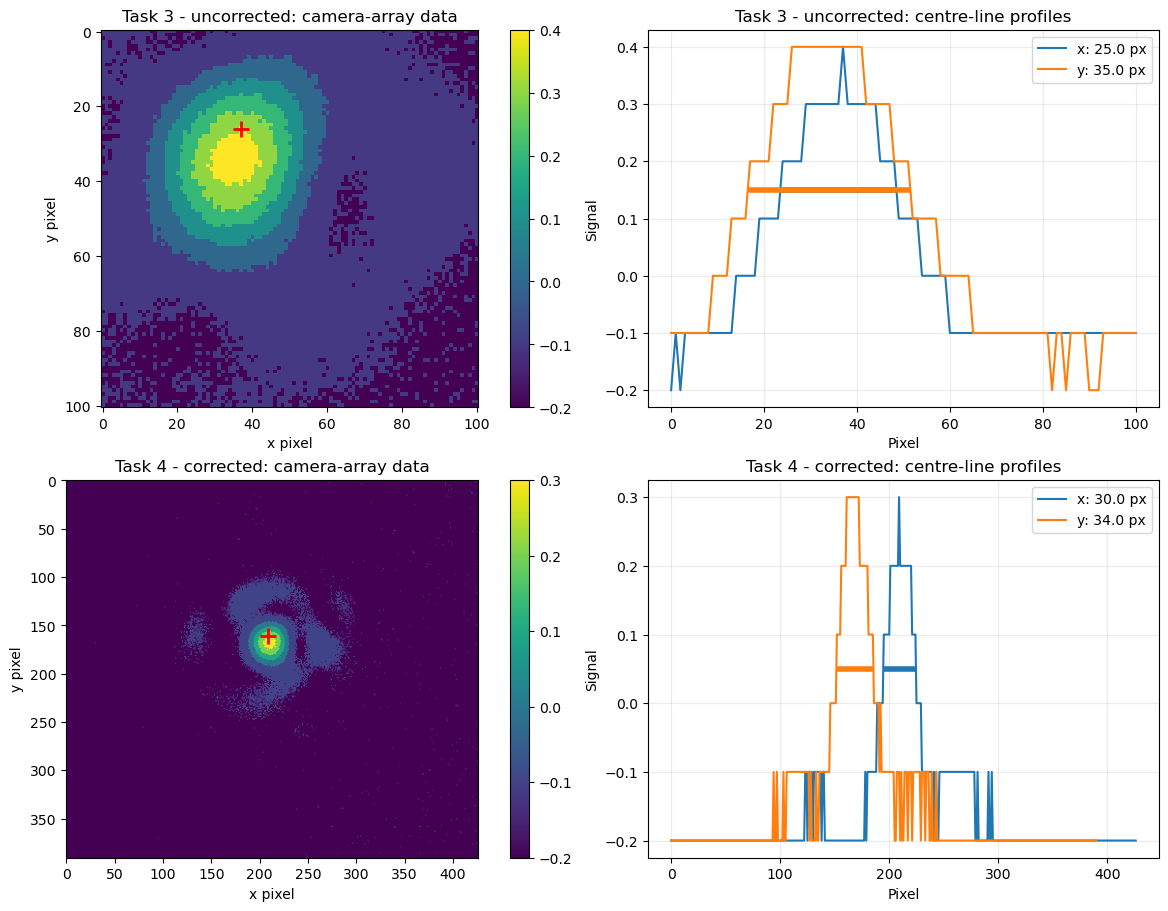

In [4]:
# Camera-array heatmaps and central FWHM profiles
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, state in enumerate([task3, task4]):
    ax = axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f"{state['label']}: camera-array data")
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px")
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
    ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal')
    ax.legend(); ax.grid(alpha=0.25)
plt.show()

In [5]:
task_8_1_p2v = 0.589
task_8_1_rms = 0.141
task_8_2_p2v = 0.552
task_8_2_rms = 0.100
task_8_3_p2v = 0.375
task_8_3_rms = 0.100
task_8_4_p2v = 0.879
task_8_4_rms = 0.139
task_8_5_p2v = 0.701
task_8_5_rms = 0.143

strehl_8_1 = np.exp(-(2 * np.pi * task_8_1_rms / WAVELENGTH_UM) ** 2)
strehl_8_2 = np.exp(-(2 * np.pi * task_8_2_rms / WAVELENGTH_UM) ** 2)
strehl_8_3 = np.exp(-(2 * np.pi * task_8_3_rms / WAVELENGTH_UM) ** 2)
strehl_8_4 = np.exp(-(2 * np.pi * task_8_4_rms / WAVELENGTH_UM) ** 2)
strehl_8_5 = np.exp(-(2 * np.pi * task_8_5_rms / WAVELENGTH_UM) ** 2)   

print(f"Task 8.1 Strehl: {strehl_8_1:.3g}")
print(f"Task 8.2 Strehl: {strehl_8_2:.3g}")
print(f"Task 8.3 Strehl: {strehl_8_3:.3g}")
print(f"Task 8.4 Strehl: {strehl_8_4:.3g}")
print(f"Task 8.5 Strehl: {strehl_8_5:.3g}")

Task 8.1 Strehl: 0.141
Task 8.2 Strehl: 0.373
Task 8.3 Strehl: 0.373
Task 8.4 Strehl: 0.149
Task 8.5 Strehl: 0.133


,FWHM source,FWHM x (data px),FWHM y (data px),Enclosed 90% energy radius (data px)
0,Task8_1.tif rendered MATLAB figure (provisional),36.0,130.8,13


,FWHM source,FWHM x (data px),FWHM y (data px),Enclosed 90% energy radius (data px)
0,Task8_2.tif rendered MATLAB figure (provisional),57.8,45.0,60


,FWHM source,FWHM x (data px),FWHM y (data px),Enclosed 90% energy radius (data px)
0,Task8_3.tif rendered MATLAB figure (provisional),43.1,39.1,39


,FWHM source,FWHM x (data px),FWHM y (data px),Enclosed 90% energy radius (data px)
0,Task8_4.tif rendered MATLAB figure (provisional),59.5,42.9,39


,FWHM source,FWHM x (data px),FWHM y (data px),Enclosed 90% energy radius (data px)
0,Task8_5.tif rendered MATLAB figure (provisional),40.3,39.4,72


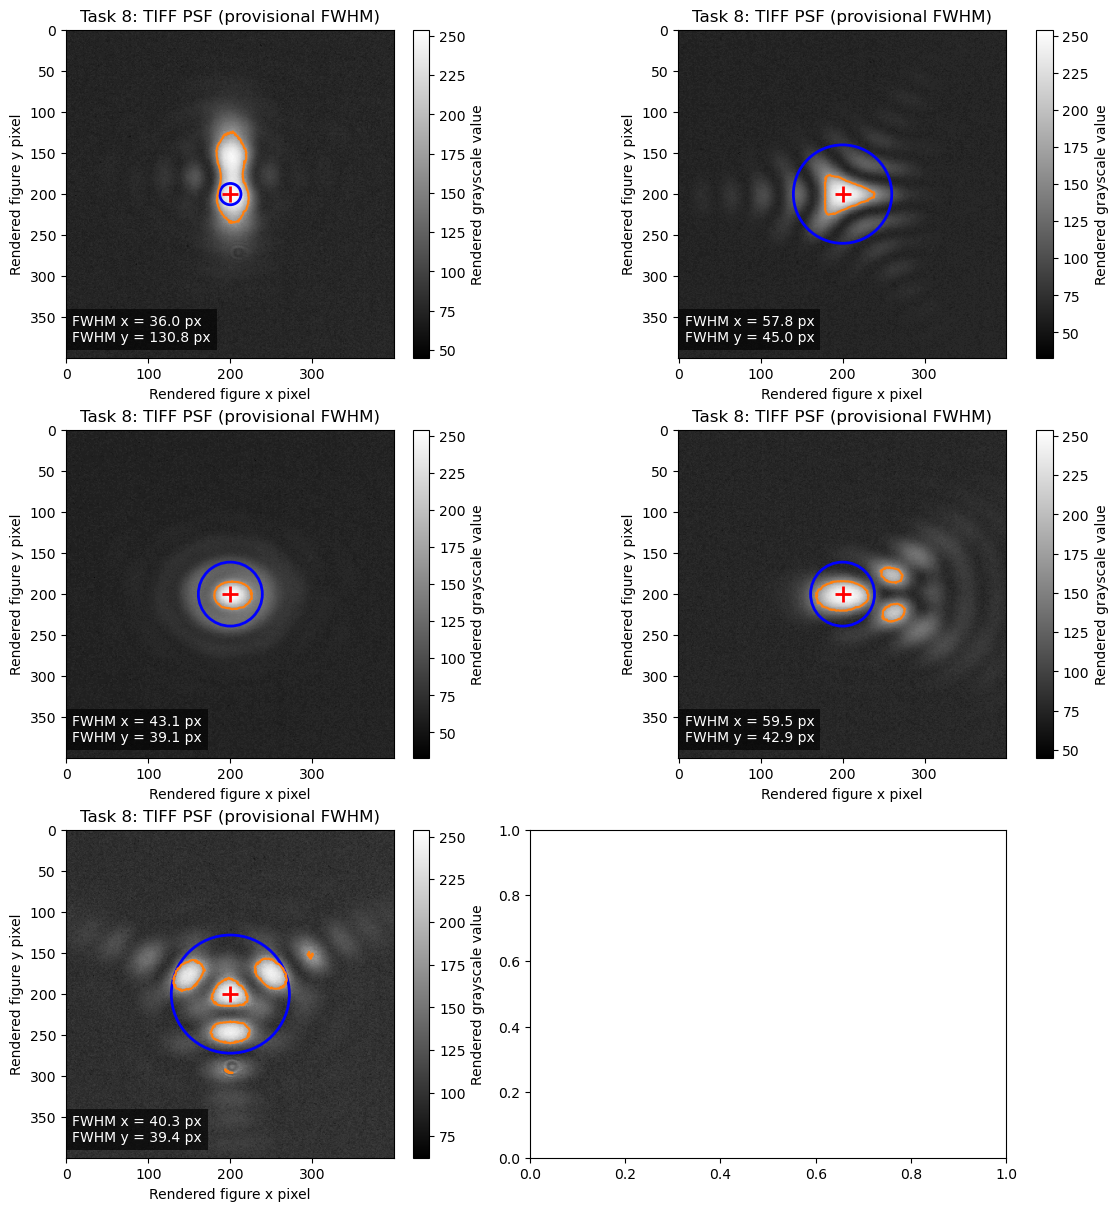

In [88]:
# TASK 7 - static wave-front correction and stability
# The low-RMS samples are treated as the observed corrected state; values below
# 1e-6 um are export underflow/sentinel values, not physical zero WFE.
def load_zernike_snapshots(filename):
    """Read one or more 20-mode Zernike exports separated by header/blank rows."""
    snapshots, current = [], []
    for line in (DATA_DIR / filename).read_text(encoding='utf-8-sig').splitlines():
        fields = [x.strip() for x in line.split('\t') if x.strip()]
        try:
            order = int(fields[0])
            value = float(fields[1].replace(',', '.'))
        except (IndexError, ValueError):
            if current:
                snapshots.append(current)
                current = []
            continue
        if order == 1 and current:
            snapshots.append(current)
            current = []
        current.append((order, value))
    if current:
        snapshots.append(current)
    return [pd.DataFrame(block, columns=['zernike_order', 'value_um']) for block in snapshots]

# task7_wfe = load_wfe('Task7_stat_wavefront_err.txt')
# task7_science = load_grid('Task7_Science_camera_data.txt')
# task7_wavefront_map = load_grid('Task7_Wavefront_map.txt')


task_8_1_p2v = 0.589
task_8_1_rms = 0.141
task_8_2_p2v = 0.552
task_8_2_rms = 0.100
task_8_3_p2v = 0.375
task_8_3_rms = 0.100
task_8_4_p2v = 0.879
task_8_4_rms = 0.139
task_8_5_p2v = 0.701
task_8_5_rms = 0.143


task8_1_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task8_first_attempt.tif').convert('RGB'), dtype=float)
task8_1_tif_gray = (task8_1_tif_rgb[..., 0] + task8_1_tif_rgb[..., 1]
                  + task8_1_tif_rgb[..., 2])/3

task8_2_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task8_second_attempt.tif').convert('RGB'), dtype=float)
task8_2_tif_gray = (task8_2_tif_rgb[..., 0] + task8_2_tif_rgb[..., 1]
                  + task8_2_tif_rgb[..., 2])/3

task8_3_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task8_third_attempt.tif').convert('RGB'), dtype=float)
task8_3_tif_gray = (task8_3_tif_rgb[..., 0] + task8_3_tif_rgb[..., 1]
                  + task8_3_tif_rgb[..., 2])/3

task8_4_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task8_fourth_attempt.tif').convert('RGB'), dtype=float)
task8_4_tif_gray = (task8_4_tif_rgb[..., 0] + task8_4_tif_rgb[..., 1]
                  + task8_4_tif_rgb[..., 2])/3

task8_5_tif_rgb = np.asarray(Image.open(DATA_DIR / 'Task8_fifth_attempt.tif').convert('RGB'), dtype=float)
task8_5_tif_gray = (task8_5_tif_rgb[..., 0] + task8_5_tif_rgb[..., 1]
                  + task8_5_tif_rgb[..., 2])/3




# task7_stability = load_zernike_snapshots('Task7_system_stability.txt')
# task7_final_zernike = load_zernike_snapshots('Task7_Zercike_vals.txt')[0]

# The export contains a machine-underflow sentinel (1.00747e-306) and two
# well-separated physical regimes.  The 0.1-um boundary lies in their empty gap.

# underflow = task7_wfe[['p2v_um', 'rms_um']].abs().max(axis=1) < 1e-6
# low_wfe = ~underflow & (task7_wfe['rms_um'] < 0.1)
# high_wfe = ~underflow & ~low_wfe

# def wfe_statistics(label, mask):
#     values = task7_wfe.loc[mask]
#     return {
#         'State': label,
#         'Samples': len(values),
#         'P2V mean (um)': values['p2v_um'].mean(),
#         'P2V SD (um)': values['p2v_um'].std(ddof=1),
#         'RMS mean (um)': values['rms_um'].mean(),
#         'RMS SD (um)': values['rms_um'].std(ddof=1),
#         'RMS min-max (um)': (values['rms_um'].min(), values['rms_um'].max()),
#     }

# task8_1_summary = pd.DataFrame([
    # wfe_statistics('Observed low-WFE state (corrected)', low_wfe),
    # wfe_statistics('Observed high-WFE state', high_wfe),
# ])
# display(task8_1_summary.style.format({
    # 'P2V mean (um)': '{:.5f}', 'P2V SD (um)': '{:.5f}',
    # 'RMS mean (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    # 'RMS min-max (um)': lambda limits: f'({limits[0]:.5f}, {limits[1]:.5f})',
# }))



# low_rms = task7_wfe.loc[low_wfe, 'rms_um'].mean()
# high_rms = task7_wfe.loc[high_wfe, 'rms_um'].mean()
# print(f'RMS reduction from the observed high- to low-WFE state: {high_rms / low_rms:.1f}x')
# print(f'Underflow/sentinel WFE samples excluded from statistics: {underflow.sum()}')

# The text science-camera export is invalid: it has no intensity variation and
# is identical to the saved wave-front map.  Task7.tif is a MATLAB figure rather
# than raw camera data, so the FWHM below is explicitly a provisional estimate.
# camera_has_signal = np.count_nonzero(np.nan_to_num(task7_science, nan=0.0)) > 0
# camera_matches_wavefront_map = np.array_equal(
    # np.nan_to_num(task7_science, nan=0.0), np.nan_to_num(task7_wavefront_map, nan=0.0)
# )
# print(f'Science-camera text export has non-zero signal: {camera_has_signal}')
# print(f'Science-camera export identical to wave-front map: {camera_matches_wavefront_map}')

def fwhm_from_rendered_profile(profile, peak_index, background):
    """Half-height width in screen pixels for a MATLAB-rendered TIFF profile."""
    peak = profile[peak_index]
    half = background + 0.5 * (peak - background)
    left_index = np.where(profile[:peak_index] < half)[0][-1]
    right_index = peak_index + 1 + np.where(profile[peak_index + 1:] < half)[0][0]
    left = left_index + (half - profile[left_index]) / (profile[left_index + 1] - profile[left_index])
    right = right_index - 1 + (half - profile[right_index - 1]) / (profile[right_index] - profile[right_index - 1])
    return dict(width_screen_px=right - left, left_screen_px=left, right_screen_px=right, half=half)

def enclosed_energy_fraction_from_rendered_profile(profile, peak_index, background, radius):
    """Fraction of the total energy enclosed within a circle centered on the peak, for a MATLAB-rendered TIFF profile."""
    peak = profile[peak_index]
    dist_from_peak = np.abs(np.arange(len(profile)) - peak_index)
    circle_mask = dist_from_peak <= radius
    masking_circle = dist_from_peak <= 300
    total_energy = np.sum((profile-background)[masking_circle])**2
    enclosed_energy = np.sum((profile-background)[circle_mask])**2
    return enclosed_energy / total_energy

# Locate the bright core inside the known plotted-image region.
search_y, search_x = slice(100, 1000), slice(400, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task8_1_tif_gray[search_y, search_x]),
                                  task8_1_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task8_1_tif_gray[120:250, 500:600].ravel(),
                           task8_1_tif_gray[1050:1150, 500:600].ravel(),
                           task8_1_tif_gray[120:250, 1200:1300].ravel()]
task8_1_tif_background = np.median(background_samples)
task8_1_tif_fwhm_x_screen = fwhm_from_rendered_profile(task8_1_tif_gray[peak_y, :], peak_x, task8_1_tif_background)
task8_1_tif_fwhm_y_screen = fwhm_from_rendered_profile(task8_1_tif_gray[:, peak_x], peak_y, task8_1_tif_background)

task8_1_tif_enclosed_energy_radius_px = 0
for ii in range (300):
    if enclosed_energy_fraction_from_rendered_profile(task8_1_tif_gray[peak_y, :], peak_x, task8_1_tif_background, ii) >= 0.9:
        task8_1_tif_enclosed_energy_radius_px = ii
        break




# Calibrated from the 200-pixel tick separation in the rendered axes.
TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task8_1_tif_fwhm_x = task8_1_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task8_1_tif_fwhm_y = task8_1_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task8_1.tif rendered MATLAB figure (provisional)',
    'FWHM x (data px)': task8_1_tif_fwhm_x,
    'FWHM y (data px)': task8_1_tif_fwhm_y,
    'Enclosed 90% energy radius (data px)': task8_1_tif_enclosed_energy_radius_px,
}])
display(tif_fwhm_summary.style.format({'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))




fig, axes = plt.subplots(3, 2, figsize=(12, 12), constrained_layout=True)


ax = axes[0, 0]
crop = 200
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task8_1_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.add_patch(Circle((peak_x - x0, peak_y - y0), radius=task8_1_tif_enclosed_energy_radius_px, fill=False, edgecolor='blue', linewidth=2))
ax.contour(task8_1_tif_gray[y0:y1, x0:x1], levels=[task8_1_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 8: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task8_1_tif_fwhm_x:.1f} px\nFWHM y = {task8_1_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')



search_y, search_x = slice(100, 1000), slice(400, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task8_2_tif_gray[search_y, search_x]), 
                                  task8_2_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task8_2_tif_gray[120:250, 500:600].ravel(),
                           task8_2_tif_gray[1050:1150, 500:600].ravel(),
                           task8_2_tif_gray[120:250, 1200:1300].ravel()]
task8_2_tif_background = np.median(background_samples)
task8_2_tif_fwhm_x_screen = fwhm_from_rendered_profile(task8_2_tif_gray[peak_y, :], peak_x, task8_2_tif_background)
task8_2_tif_fwhm_y_screen = fwhm_from_rendered_profile(task8_2_tif_gray[:, peak_x], peak_y, task8_2_tif_background)

for ii in range (300):
    if enclosed_energy_fraction_from_rendered_profile(task8_2_tif_gray[peak_y, :], peak_x, task8_2_tif_background, ii) >= 0.9:
        task8_2_tif_enclosed_energy_radius_px = ii
        break


# Calibrated from the 200-pixel tick separation in the rendered axes.
TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task8_2_tif_fwhm_x = task8_2_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task8_2_tif_fwhm_y = task8_2_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task8_2.tif rendered MATLAB figure (provisional)',
    # 'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task8_2_tif_fwhm_x,
    'FWHM y (data px)': task8_2_tif_fwhm_y,
    'Enclosed 90% energy radius (data px)': task8_2_tif_enclosed_energy_radius_px
}])
display(tif_fwhm_summary.style.format({'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))


ax = axes[0, 1]
crop = 200
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task8_2_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.add_patch(Circle((peak_x - x0, peak_y - y0), radius=task8_2_tif_enclosed_energy_radius_px, fill=False, edgecolor='blue', linewidth=2))
ax.contour(task8_2_tif_gray[y0:y1, x0:x1], levels=[task8_2_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 8: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task8_2_tif_fwhm_x:.1f} px\nFWHM y = {task8_2_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')



search_y, search_x = slice(100, 1000), slice(400, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task8_3_tif_gray[search_y, search_x]), 
                                  task8_3_tif_gray[search_y, search_x].shape)
peak_y += search_y.start 
peak_x += search_x.start
background_samples = np.r_[task8_3_tif_gray[120:250, 500:600].ravel(),
                           task8_3_tif_gray[1050:1150, 500:600].ravel(),
                           task8_3_tif_gray[120:250, 1200:1300].ravel()]
task8_3_tif_background = np.median(background_samples)
task8_3_tif_fwhm_x_screen = fwhm_from_rendered_profile(task8_3_tif_gray[peak_y, :], peak_x, task8_3_tif_background)
task8_3_tif_fwhm_y_screen = fwhm_from_rendered_profile(task8_3_tif_gray[:, peak_x], peak_y, task8_3_tif_background)

for ii in range (300):
    if enclosed_energy_fraction_from_rendered_profile(task8_3_tif_gray[peak_y, :], peak_x, task8_3_tif_background, ii) >= 0.9:
        task8_3_tif_enclosed_energy_radius_px = ii
        break


TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task8_3_tif_fwhm_x = task8_3_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task8_3_tif_fwhm_y = task8_3_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task8_3.tif rendered MATLAB figure (provisional)',
    # 'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task8_3_tif_fwhm_x,
    'FWHM y (data px)': task8_3_tif_fwhm_y,
    'Enclosed 90% energy radius (data px)': task8_3_tif_enclosed_energy_radius_px
}])
display(tif_fwhm_summary.style.format({'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))

ax = axes[1, 0]
crop = 200
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task8_3_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.add_patch(Circle((peak_x - x0, peak_y - y0), radius=task8_3_tif_enclosed_energy_radius_px, fill=False, edgecolor='blue', linewidth=2))
ax.contour(task8_3_tif_gray[y0:y1, x0:x1], levels=[task8_3_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 8: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task8_3_tif_fwhm_x:.1f} px\nFWHM y = {task8_3_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')



search_y, search_x = slice(100, 1000), slice(400, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task8_4_tif_gray[search_y, search_x]), 
                                  task8_4_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task8_4_tif_gray[120:250, 500:600].ravel(),
                           task8_4_tif_gray[1050:1150, 500:600].ravel(),
                           task8_4_tif_gray[120:250, 1200:1300].ravel()]
task8_4_tif_background = np.median(background_samples)
task8_4_tif_fwhm_x_screen = fwhm_from_rendered_profile(task8_4_tif_gray[peak_y, :], peak_x, task8_4_tif_background)
task8_4_tif_fwhm_y_screen = fwhm_from_rendered_profile(task8_4_tif_gray[:, peak_x], peak_y, task8_4_tif_background)

for ii in range (300):
    if enclosed_energy_fraction_from_rendered_profile(task8_4_tif_gray[peak_y, :], peak_x, task8_4_tif_background, ii) >= 0.9:
        task8_4_tif_enclosed_energy_radius_px = ii
        break

TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task8_4_tif_fwhm_x = task8_4_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task8_4_tif_fwhm_y = task8_4_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task8_4.tif rendered MATLAB figure (provisional)',
    # 'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task8_4_tif_fwhm_x,
    'FWHM y (data px)': task8_4_tif_fwhm_y,
    'Enclosed 90% energy radius (data px)': task8_4_tif_enclosed_energy_radius_px
}])
display(tif_fwhm_summary.style.format({'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))

ax = axes[1, 1]
crop = 200
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task8_4_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.add_patch(Circle((peak_x - x0, peak_y - y0), radius=task8_4_tif_enclosed_energy_radius_px, fill=False, edgecolor='blue', linewidth=2))
ax.contour(task8_4_tif_gray[y0:y1, x0:x1], levels=[task8_4_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 8: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task8_4_tif_fwhm_x:.1f} px\nFWHM y = {task8_4_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')




search_y, search_x = slice(100, 1000), slice(400, 1000)
peak_y, peak_x = np.unravel_index(np.argmax(task8_5_tif_gray[search_y, search_x]), 
                                  task8_5_tif_gray[search_y, search_x].shape)
peak_y += search_y.start
peak_x += search_x.start
background_samples = np.r_[task8_5_tif_gray[120:250, 500:600].ravel(),
                           task8_5_tif_gray[1050:1150, 500:600].ravel(),
                           task8_5_tif_gray[120:250, 1200:1300].ravel()]
task8_5_tif_background = np.median(background_samples)
task8_5_tif_fwhm_x_screen = fwhm_from_rendered_profile(task8_5_tif_gray[peak_y, :], peak_x, task8_5_tif_background)
task8_5_tif_fwhm_y_screen = fwhm_from_rendered_profile(task8_5_tif_gray[:, peak_x], peak_y, task8_5_tif_background)

for ii in range (300):
    if enclosed_energy_fraction_from_rendered_profile(task8_5_tif_gray[peak_y, :], peak_x, task8_5_tif_background, ii) >= 0.9:
        task8_5_tif_enclosed_energy_radius_px = ii
        break

TIF_X_DATA_PX_PER_SCREEN_PX = 200 / 209
TIF_Y_DATA_PX_PER_SCREEN_PX = 200 / 167
task8_5_tif_fwhm_x = task8_5_tif_fwhm_x_screen['width_screen_px'] * TIF_X_DATA_PX_PER_SCREEN_PX
task8_5_tif_fwhm_y = task8_5_tif_fwhm_y_screen['width_screen_px'] * TIF_Y_DATA_PX_PER_SCREEN_PX
tif_fwhm_summary = pd.DataFrame([{
    'FWHM source': 'Task8_5.tif rendered MATLAB figure (provisional)',
    # 'Peak plotted value (%)': 84.468,
    'FWHM x (data px)': task8_5_tif_fwhm_x,
    'FWHM y (data px)': task8_5_tif_fwhm_y,
    'Enclosed 90% energy radius (data px)': task8_5_tif_enclosed_energy_radius_px,
}])
display(tif_fwhm_summary.style.format({'FWHM x (data px)': '{:.1f}',
                                       'FWHM y (data px)': '{:.1f}'}))

ax = axes[2, 0]
crop = 200
y0, y1 = peak_y - crop, peak_y + crop
x0, x1 = peak_x - crop, peak_x + crop
im = ax.imshow(task8_5_tif_gray[y0:y1, x0:x1], origin='upper', cmap='gray')
ax.plot(peak_x - x0, peak_y - y0, 'r+', ms=12, mew=2)
ax.add_patch(Circle((peak_x - x0, peak_y - y0), radius=task8_5_tif_enclosed_energy_radius_px, fill=False, edgecolor='blue', linewidth=2))
ax.contour(task8_5_tif_gray[y0:y1, x0:x1], levels=[task8_5_tif_fwhm_x_screen['half']],
           colors='tab:orange', linewidths=1.5)
ax.set(title='Task 8: TIFF PSF (provisional FWHM)', xlabel='Rendered figure x pixel',
       ylabel='Rendered figure y pixel')
ax.text(0.02, 0.04, f'FWHM x = {task8_5_tif_fwhm_x:.1f} px\nFWHM y = {task8_5_tif_fwhm_y:.1f} px',
        transform=ax.transAxes, color='white', va='bottom',
        bbox=dict(facecolor='black', alpha=0.65, edgecolor='none'))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Rendered grayscale value')
plt.savefig(DATA_DIR / 'Task8_tif_psf.png', dpi=300)
# plt.tight_layout()
plt.show()

In [85]:
rcparams = {'figure.dpi': 150, 'savefig.dpi': 300}

In [86]:
task8_1_tif_enclosed_energy_radius_px

13

In [59]:
task8_1_tif_background,

(81.0,)

In [41]:
task9_1 = analyse_state('Task 9 - corrected', 'Task9_uncorrected_WFE.txt', 'Task9_PSF.txt')
task9_2 = analyse_state('Task 9 - uncorrected', 'Task9_corrected_WFE.txt', 'Task9_PSF.txt')

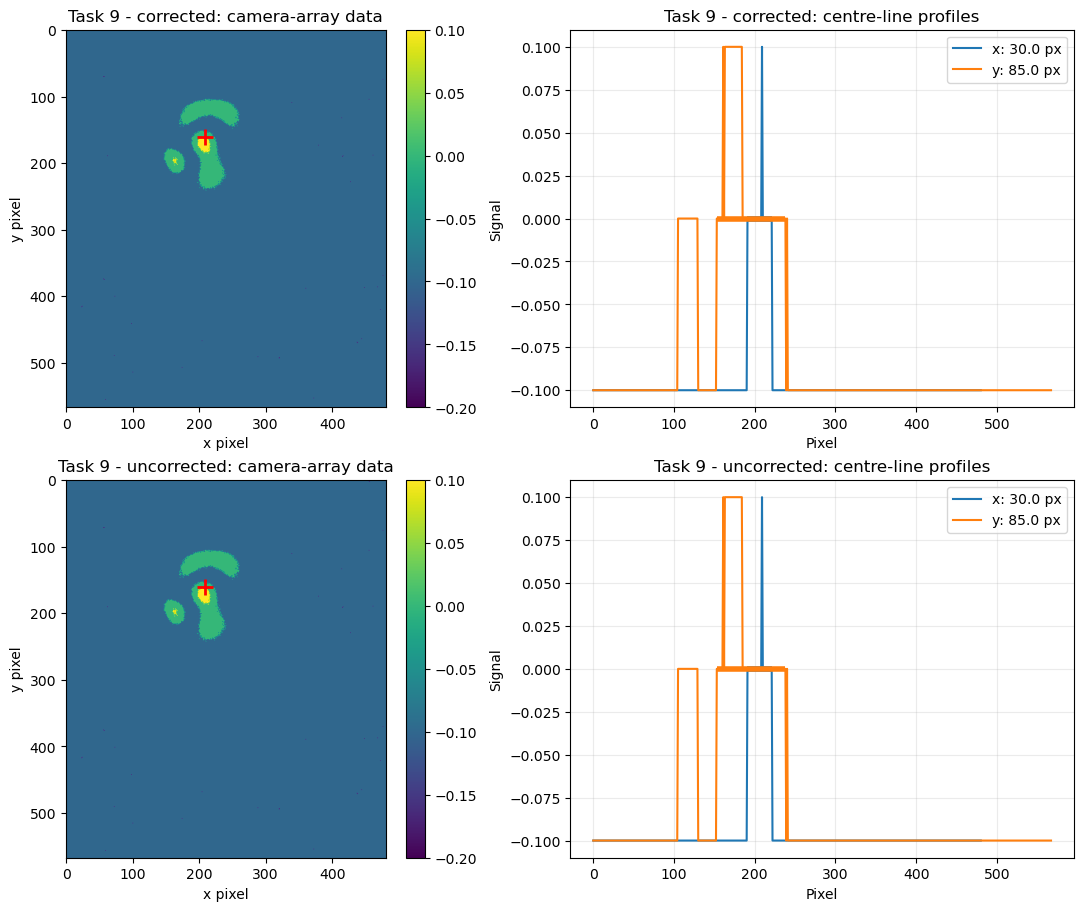

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, state in enumerate([task9_1, task9_2]):
    ax = axes[row, 0]
    im = ax.imshow(state['image'], origin='upper', cmap='viridis')
    ax.plot(state['peak_col'], state['peak_row'], 'r+', ms=12, mew=2)
    ax.set_title(f"{state['label']}: camera-array data")
    ax.set_xlabel('x pixel'); ax.set_ylabel('y pixel')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row, 1]
    for profile, axis_name, colour, result in [
        (state['x_profile'], 'x', 'tab:blue', state['x_fwhm']),
        (state['y_profile'], 'y', 'tab:orange', state['y_fwhm']),
    ]:
        x = np.arange(len(profile))
        ax.plot(x, profile, color=colour, label=f"{axis_name}: {result['width_px']:.1f} px")
        ax.hlines(result['half'], result['left_px'], result['right_px'], color=colour, lw=4)
    ax.set(title=f"{state['label']}: centre-line profiles", xlabel='Pixel', ylabel='Signal')
    ax.legend(); ax.grid(alpha=0.25)
plt.show()

In [43]:
summary = pd.DataFrame([
    {'State': task9_1['label'], 'P2V WFE (um)': task9_1['p2v_mean_um'], 'P2V SD (um)': task9_1['p2v_sd_um'],
     'RMS WFE (um)': task9_1['rms_mean_um'], 'RMS SD (um)': task9_1['rms_sd_um'],
     'Strehl (Marechal)': task9_1['strehl_marechal'],
     'FWHM x (px)': task9_1['x_fwhm']['width_px'], 'FWHM y (px)': task9_1['y_fwhm']['width_px'],
     'Camera array': f"{task9_1['image'].shape[0]} x {task9_1['image'].shape[1]}"},
    {'State': task9_2['label'], 'P2V WFE (um)': task9_2['p2v_mean_um'], 'P2V SD (um)': task9_2['p2v_sd_um'],
     'RMS WFE (um)': task9_2['rms_mean_um'], 'RMS SD (um)': task9_2['rms_sd_um'],
     'Strehl (Marechal)': task9_2['strehl_marechal'],
     'FWHM x (px)': task9_2['x_fwhm']['width_px'], 'FWHM y (px)': task9_2['y_fwhm']['width_px'],
     'Camera array': f"{task9_2['image'].shape[0]} x {task9_2['image'].shape[1]}"},
])

display(summary.style.format({
    'P2V WFE (um)': '{:.4f}', 'P2V SD (um)': '{:.4f}',
    'RMS WFE (um)': '{:.5f}', 'RMS SD (um)': '{:.5f}',
    'Strehl (Marechal)': '{:.3g}', 'FWHM x (px)': '{:.1f}', 'FWHM y (px)': '{:.1f}',
}))

print(f"RMS reduction factor: {task9_1['rms_mean_um'] / task9_2['rms_mean_um']:.2f}x")
print(f"P2V reduction factor: {task9_1['p2v_mean_um'] / task9_2['p2v_mean_um']:.2f}x")

,State,P2V WFE (um),P2V SD (um),RMS WFE (um),RMS SD (um),Strehl (Marechal),FWHM x (px),FWHM y (px),Camera array
0,Task 9 - corrected,0.8348,0.0693,0.21306,0.02347,0.0114,30.0,85.0,568 x 481
1,Task 9 - uncorrected,14.5541,0.0975,3.75018,0.03338,0,30.0,85.0,568 x 481


RMS reduction factor: 0.06x
P2V reduction factor: 0.06x
